# 1. Dataset candidates

| Candidate | Source | Samples | Features | License |
|---|---|---|---|---|
| Wine | UCI ML Repository (also in scikit-learn) | 178 | 13 | CC BY 4.0 |
| Breast Cancer Wisconsin (Diagnostic) | UCI ML Repository (also in scikit-learn) | 569 | 30 | CC BY 4.0 |
| Palmer Penguins | Kaggle / allisonhorst/palmerpenguins | 344 | 7 | CC0 |

**Chosen: Wine.** All 13 features are numeric with no missing values, and the 3 classes are well separated. The data is tiny (178 rows), so training is instant and we can run many experiments. No download is needed. Breast Cancer is binary, and Penguins has missing values and mixed types.
Since we're a french team, we chose the Wine dataset because it is related to wine.

# 2. Problem definition

- **Input**: 13 chemical measurements of a wine (alcohol, malic acid, ...)
- **Target**: the grape cultivar (`class_0`, `class_1`, `class_2`)
- **Problem type**: multiclass classification (3 classes)

In [1]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame
print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


# 3. Evaluation metric

In [2]:
counts = df["target"].value_counts().sort_index()
pd.DataFrame({
    "class": wine.target_names,
    "samples": counts.values,
    "ratio (%)": (counts / len(df) * 100).round(1).values,
}).set_index("class")

,samples,ratio (%)
class,,
class_0,59,33.1
class_1,71,39.9
class_2,48,27.0


The classes are 59 : 71 : 48 (33% / 40% / 27%): mildly imbalanced, but no class is rare, so **accuracy** a fair metric and easy to read. We also look at the accuracy of each class separately, to check that a model is not good on one class only.

# 4. Common-sense baseline

Always answer with the most frequent class. It gives a reference since a real model is only useful if it clearly beats it.

Always predicting `class_1` gives about 40% accuracy.

In [3]:
y = df["target"]
majority = y.mode()[0]
pred = pd.Series(majority, index=y.index)
baseline_acc = (pred == y).mean()
print(f"Most frequent class: {wine.target_names[majority]}")
print(f"Baseline accuracy: {baseline_acc:.3f}")

Most frequent class: class_1
Baseline accuracy: 0.399


**Accuracy per class**: for each type of wine, how many did the baseline get right? It only knows `class_1`, so it is 100% right on `class_1` and 0% right on the others.

In [4]:
per_class = pd.DataFrame({
    "class": wine.target_names,
    "wines": y.value_counts().sort_index().values,
    "correct": (pred == y).groupby(y).sum().values,
})
per_class["accuracy (%)"] = (per_class["correct"] / per_class["wines"] * 100).round(1)
per_class.set_index("class")

,wines,correct,accuracy (%)
class,,,
class_0,59,0,0.0
class_1,71,71,100.0
class_2,48,0,0.0


# 5. Data exploration

First we look at the type of each feature, the missing values and the basic statistics.

In [5]:
import matplotlib.pyplot as plt

pd.DataFrame({"dtype": df.dtypes, "missing": df.isna().sum()})

,dtype,missing
alcohol,float64,0
malic_acid,float64,0
ash,float64,0
alcalinity_of_ash,float64,0
magnesium,float64,0
total_phenols,float64,0
flavanoids,float64,0
nonflavanoid_phenols,float64,0
proanthocyanins,float64,0
color_intensity,float64,0


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


All the features and the target are numeric and there are **no missing values**. The ranges are very different (`proline` goes from 278 to 1680, `hue` from 0.48 to 1.71), so we will need to normalize.

**Graph 1: class distribution (bar chart)**

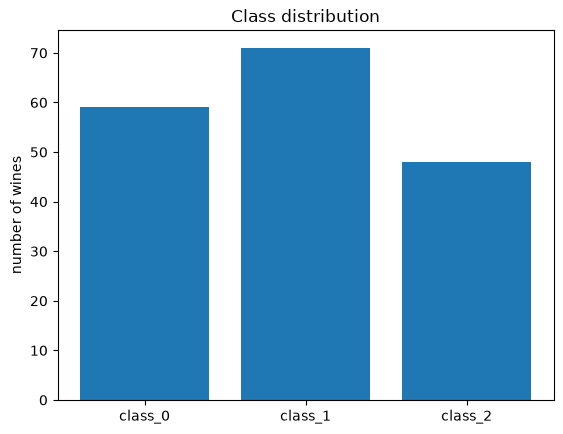

In [7]:
counts = df["target"].value_counts().sort_index()
plt.bar(wine.target_names, counts.values)
plt.ylabel("number of wines")
plt.title("Class distribution")
plt.show()

**Graph 2: distribution of each feature (histograms)**

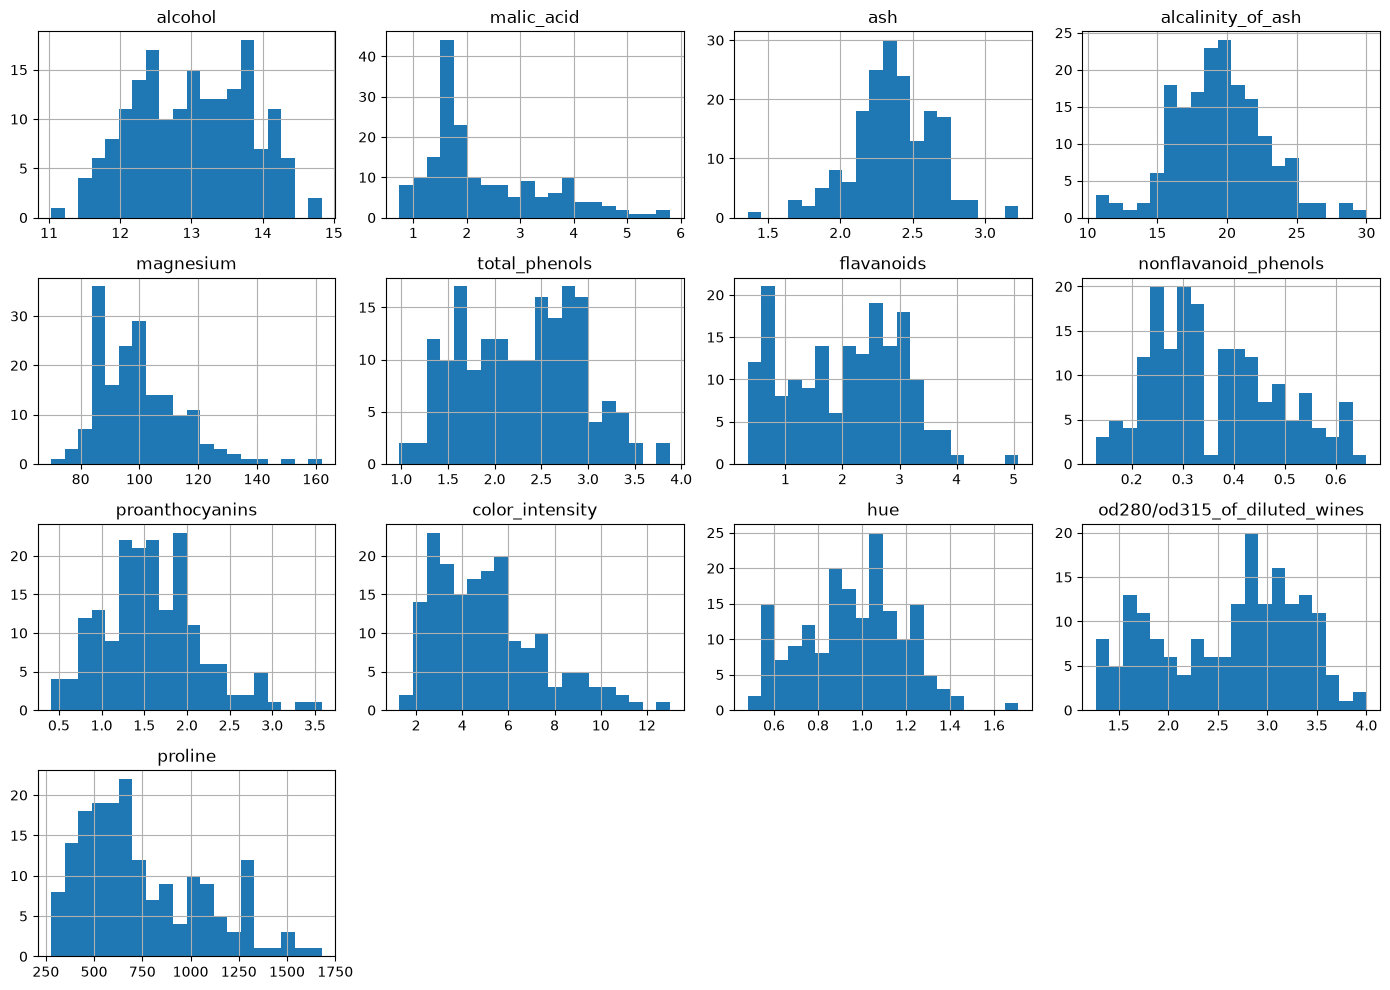

In [8]:
X = df.drop(columns="target")
X.hist(bins=20, figsize=(14, 10))
plt.tight_layout()
plt.show()

**Graph 3: some features by class (boxplots)**

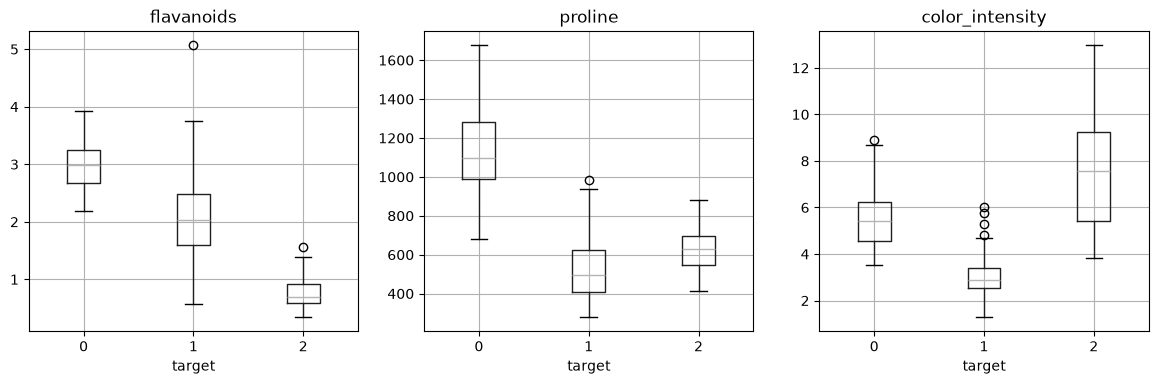

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["flavanoids", "proline", "color_intensity"]):
    df.boxplot(column=col, by="target", ax=ax)
    ax.set_title(col)
plt.suptitle("")
plt.show()

- The classes are a bit imbalanced (59 / 71 / 48), as in section 3.
- Most features look like a bell curve, with a few outliers (`magnesium`, `malic_acid`). `proline` is skewed to the right.
- `flavanoids`, `proline` and `color_intensity` are clearly different between the classes, so the problem should be easy to learn.
- The rows are sorted by class, so we have to shuffle before splitting.

# 6. Train / final test split

**80% training / 20% final test.** With less than 1,000 samples we can skip the check-up test set. We only have 178 wines, so a check-up set (about 27 wines) would be too small and we would lose training data. We will choose our models with cross-validation instead.

The split is stratified (same class ratio in each set) and shuffled, because the data is sorted by class.

In [10]:
from sklearn.model_selection import train_test_split

train_df, final_test_df = train_test_split(
    df, test_size=0.2, stratify=df["target"], shuffle=True, random_state=42
)
pd.DataFrame({
    "train": train_df["target"].value_counts().sort_index(),
    "final test": final_test_df["target"].value_counts().sort_index(),
}).set_index(wine.target_names).assign(
    train_ratio=lambda t: (t["train"] / len(train_df) * 100).round(1),
    test_ratio=lambda t: (t["final test"] / len(final_test_df) * 100).round(1),
)

,train,final test,train_ratio,test_ratio
class_0,47,12,33.1,33.3
class_1,57,14,40.1,38.9
class_2,38,10,26.8,27.8


In [11]:
print("train:", train_df.shape, "| final test:", final_test_df.shape)

train: (142, 14) | final test: (36, 14)


We save the final test set in a file and we don't touch it until the end. From now on we only load the training data.

In [12]:
import os

os.makedirs("../../data", exist_ok=True)
train_df.to_csv("../../data/train.csv", index=False)
final_test_df.to_csv("../../data/final_test.csv", index=False)

# From now on: only the training data
train = pd.read_csv("../../data/train.csv")
print(train.shape)
train.head()

(142, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0,0
1,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0,0
2,13.39,1.77,2.62,16.1,93.0,2.85,2.94,0.34,1.45,4.80,0.92,3.22,1195.0,0
3,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0,0
4,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0,2


# 7. K-fold cross-validation

**K = 5.** We have 142 wines for training, so each validation fold has about 28 wines. With K = 10 a fold would have only 14 wines, so the scores would be too noisy. With K = 3 the models would train on only 2/3 of the data. 5 is a good compromise.

The K-fold is stratified and shuffled. From Week 12 we will compare all the models with the average accuracy over the 5 folds.

In [13]:
from sklearn.model_selection import StratifiedKFold

X_train = train.drop(columns="target").to_numpy()
y_train = train["target"].to_numpy()

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for i, (tr_idx, val_idx) in enumerate(kfold.split(X_train, y_train)):
    counts = pd.Series(y_train[val_idx]).value_counts().sort_index()
    rows.append({"fold": i + 1, "train": len(tr_idx), "validation": len(val_idx),
                 "val class_0": counts[0], "val class_1": counts[1], "val class_2": counts[2]})
pd.DataFrame(rows).set_index("fold")

,train,validation,val class_0,val class_1,val class_2
fold,,,,,
1,113,29,10,12,7
2,113,29,10,12,7
3,114,28,9,11,8
4,114,28,9,11,8
5,114,28,9,11,8


# 8. Preprocessing

**Missing values.** There are none, so nothing to fill. (If there were, we would use the median of the training data, because outliers don't change it.)

In [14]:
print("Missing values in the training data:", train.isna().sum().sum())

Missing values in the training data: 0


**Categorical features.** None: all 13 features are numeric, so no one-hot encoding. The target is already an integer (0, 1, 2), so we can use it with `sparse_categorical_crossentropy` in Keras.

**Normalization.** Like in the course, we put each feature to mean 0 and standard deviation 1. The features have very different scales (`proline` is around 750, `hue` around 1) and a neural network trains badly like this. The mean and std are computed on the **training data only**, and the final test set will be scaled later with these same values.

In [15]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train_norm = (X_train - mean) / std

**Before and after** (training data):

In [16]:
cols = train.drop(columns="target").columns
print("BEFORE")
display(pd.DataFrame(X_train, columns=cols).head().round(2))
print("AFTER")
display(pd.DataFrame(X_train_norm, columns=cols).head().round(2))

BEFORE


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0
1,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0
2,13.39,1.77,2.62,16.1,93.0,2.85,2.94,0.34,1.45,4.80,0.92,3.22,1195.0
3,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0
4,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0


AFTER


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.39,-0.64,1.78,-1.22,0.70,0.53,0.73,-0.17,-0.42,-0.17,0.62,0.25,0.47
1,0.95,-0.77,1.25,0.85,0.09,1.17,1.33,-0.59,1.35,0.31,1.07,0.15,1.82
2,0.52,-0.52,0.95,-1.05,-0.45,0.93,1.01,-0.17,-0.26,-0.08,-0.13,0.89,1.52
3,0.97,-0.56,0.17,-1.08,-0.71,0.53,0.82,-0.59,0.36,0.26,0.89,0.43,1.93
4,0.44,0.82,0.06,0.56,-0.51,-0.56,-1.29,0.76,-0.61,1.47,-1.77,-1.44,-0.30


In [17]:
pd.DataFrame({
    "mean before": X_train.mean(axis=0),
    "std before": X_train.std(axis=0),
    "mean after": X_train_norm.mean(axis=0),
    "std after": X_train_norm.std(axis=0),
}, index=cols).round(2) + 0  # + 0 removes the -0.0

,mean before,std before,mean after,std after
alcohol,12.97,0.80,0.0,1.0
malic_acid,2.34,1.10,0.0,1.0
ash,2.36,0.27,0.0,1.0
alcalinity_of_ash,19.63,3.37,0.0,1.0
magnesium,99.63,14.88,0.0,1.0
total_phenols,2.27,0.62,0.0,1.0
flavanoids,1.99,0.95,0.0,1.0
nonflavanoid_phenols,0.36,0.12,0.0,1.0
proanthocyanins,1.60,0.58,0.0,1.0
color_intensity,4.99,2.33,0.0,1.0


# 9. Data leakage check

In [18]:
# 1. Is there a feature that is (almost) the target itself?
corr = train.corr()["target"].drop("target").abs().sort_values(ascending=False)
print(corr.head(3).round(2))

# 2. Are there duplicated wines (that could be in both train and test)?
print("Duplicated rows in the full dataset:", df.duplicated().sum())

flavanoids                      0.87
od280/od315_of_diluted_wines    0.78
total_phenols                   0.71
Name: target, dtype: float64
Duplicated rows in the full dataset: 0


- **Feature known only after the target?** No. The 13 features are chemical measurements of the wine, so we can have them for any new wine.
- **Feature that is a copy of the target?** No, the highest correlation is 0.87 (`flavanoids`).
- **Duplicated wines that could be in both train and test?** No duplicates.
- **Split before preprocessing?** Yes, and the final test set is saved and not opened.
- **Mean and std from the training data only?** Yes.
- **Rows sorted by class?** Yes, but the split and the K-fold shuffle the data.

One small point: we normalize the whole training set once, so each validation fold has a tiny influence on the mean and std. With 142 samples it is negligible. To be strict we could compute them inside each fold in Week 12.